# Monte Carlo Insurance Loss Simulation

**Personal actuarial project** · Aggregate loss model dengan frekuensi Poisson, severity Lognormal, dan pengukuran risiko VaR/TVaR.

---
## 1. Project Overview

Proyek ini mensimulasikan **total kerugian klaim tahunan** sebuah portofolio asuransi menggunakan **simulasi Monte Carlo**.
Alurnya:

1. Bangkitkan **jumlah klaim** dalam setahun (frekuensi) dari distribusi Poisson.
2. Bangkitkan **besar tiap klaim** (severity) dari distribusi Lognormal.
3. Jumlahkan semua klaim menjadi **total kerugian tahunan**.
4. Ulangi 10.000 kali untuk mendapatkan **distribusi** total kerugian.
5. Ukur risikonya: rata-rata, standar deviasi, **VaR**, dan **TVaR**.

> **Catatan transparansi.** Semua parameter pada notebook ini adalah **asumsi ilustratif**, bukan hasil estimasi dari data perusahaan asuransi nyata.
> Tujuan proyek adalah memahami *metodenya*, bukan memprediksi kerugian perusahaan tertentu.

## 2. Background

Perusahaan asuransi menjual janji: membayar klaim di masa depan dengan imbalan premi hari ini. Masalahnya, **klaim bersifat acak** pada dua level sekaligus:

- **Berapa banyak** klaim yang terjadi tahun ini? (bisa 1, bisa 9)
- **Seberapa besar** setiap klaim? (kebanyakan kecil, sesekali sangat besar)

Seorang aktuaris perlu menjawab pertanyaan seperti:

| Pertanyaan | Kebutuhan |
|---|---|
| Berapa kerugian yang *diharapkan* per tahun? | Penetapan premi dasar (*pure premium*) |
| Seberapa besar *ketidakpastiannya*? | Margin risiko |
| Seberapa buruk tahun terburuk yang masih "wajar"? | Modal / cadangan solvabilitas |

Distribusi total kerugian $S$ adalah penjumlahan sejumlah acak dari variabel acak. Bentuk analitiknya melibatkan konvolusi berulang dan umumnya **tidak tertulis rapi**.
Simulasi Monte Carlo menghindari kerumitan itu: kita cukup *mengundi* banyak "tahun hipotetis" lalu membaca distribusinya dari hasil undian.

Ukuran risiko seperti VaR dan TVaR dipakai secara luas dalam manajemen risiko asuransi. Sebagai contoh, regulasi Solvency II menggunakan VaR, sedangkan Swiss Solvency Test menggunakan TVaR.

## 3. Objectives and Benefits

**Tujuan**

1. Membangun model *aggregate loss* sederhana dengan Python.
2. Menggunakan Monte Carlo untuk memperoleh distribusi total kerugian tahunan.
3. Menghitung dan menafsirkan **Expected Loss, Standard Deviation, VaR 95%/99%, TVaR 95%/99%**.
4. **Memvalidasi** simulasi dengan membandingkannya terhadap hasil teoretis.
5. Menganalisis **konvergensi** dan **sensitivitas** hasil terhadap parameter.

**Manfaat**

- Melatih alur kerja aktuaria: asumsi → model → simulasi → validasi → interpretasi.
- Menjadi dasar pengembangan ke model yang lebih realistis (data nyata, deductible, reinsurance).
- Menjadi portofolio yang bisa dijelaskan secara utuh pada wawancara.

## 4. Theoretical Foundation

### 4.1 Aggregate Loss Model

$$S = \sum_{i=1}^{N} X_i, \qquad S = 0 \text{ jika } N = 0$$

- $N$ : jumlah klaim dalam satu tahun (frekuensi)
- $X_i$ : besar klaim ke-$i$ (severity), saling bebas dan berdistribusi identik
- $N$ dan $X_i$ diasumsikan **saling bebas**

### 4.2 Frekuensi: Poisson

$$P(N=k) = \frac{e^{-\lambda}\lambda^k}{k!}, \qquad E[N] = \mathrm{Var}(N) = \lambda$$

**Mengapa Poisson?** Ia memodelkan *banyaknya kejadian acak yang jarang dan saling bebas dalam suatu periode*, dan hanya butuh satu parameter ($\lambda$ = rata-rata klaim per tahun). Ini titik awal standar dalam aktuaria. Keterbatasan: Poisson mengharuskan mean = varians, sedangkan data nyata sering *overdispersed* (varians lebih besar), sehingga Negative Binomial sering dipakai sebagai perluasan.

### 4.3 Severity: Lognormal

$X \sim \text{Lognormal}(\mu,\sigma)$ berarti $\ln X \sim \mathcal{N}(\mu,\sigma^2)$.

$$E[X] = e^{\mu+\sigma^2/2}, \qquad \text{Median}(X) = e^{\mu}, \qquad E[X^2] = e^{2\mu+2\sigma^2}$$

**Mengapa Lognormal?** Nilainya selalu positif, miring ke kanan (kebanyakan klaim kecil, sedikit klaim sangat besar), dan ekornya cukup tebal untuk menggambarkan klaim besar. Keterbatasan: untuk risiko dengan ekor sangat tebal (misalnya bencana), Pareto atau distribusi *heavy-tailed* lain bisa lebih sesuai.

### 4.4 Momen teoretis (compound Poisson)

Karena $N$ Poisson dan bebas dari $X_i$:

$$E[S] = \lambda\,E[X], \qquad \mathrm{Var}(S) = \lambda\,E[X^2]$$

Rumus ini sangat berguna: kita punya **jawaban pasti** untuk mean dan varians, sehingga bisa dipakai untuk **memeriksa apakah simulasi kita benar**.

### 4.5 Monte Carlo

Berdasarkan *Law of Large Numbers*, rata-rata dari banyak simulasi mendekati nilai harapan sebenarnya. Galat estimasinya (*standard error*) adalah

$$\mathrm{SE}(\bar S) = \frac{s}{\sqrt{n}}$$

sehingga untuk menurunkan galat setengahnya kita perlu **empat kali** lebih banyak simulasi.

### 4.6 Ukuran risiko

Untuk tingkat kepercayaan $\alpha$ (misalnya 95% atau 99%):

$$\mathrm{VaR}_\alpha(S) = \inf\{s : P(S \le s) \ge \alpha\} \qquad \text{(kuantil ke-}\alpha\text{)}$$

$$\mathrm{TVaR}_\alpha(S) = E\left[\,S \mid S \ge \mathrm{VaR}_\alpha\,\right] \qquad \text{(rata-rata kerugian di dalam ekor)}$$

- **VaR** menjawab: *"Kerugian tidak akan melebihi angka ini dengan peluang $\alpha$."*
- **TVaR** menjawab: *"Jika kita sudah melewati VaR, rata-rata seburuk apa?"*
- Selalu berlaku $\mathrm{TVaR}_\alpha \ge \mathrm{VaR}_\alpha$.

## 5. Model Assumptions and Parameters

| Komponen | Distribusi | Parameter | Keterangan |
|---|---|---|---|
| Frekuensi klaim $N$ | Poisson | $\lambda = 4$ | Rata-rata 4 klaim per tahun untuk seluruh portofolio |
| Severity $X$ | Lognormal | $\mu = 10$ | Median klaim = $e^{10} \approx$ 22.026 |
| Severity $X$ | Lognormal | $\sigma = 0.8$ | Tingkat variasi/kemiringan klaim |
| Simulasi | Monte Carlo | 10.000 iterasi | Setiap iterasi = satu "tahun hipotetis" |
| Seed | - | 42 | Agar hasil dapat direproduksi |

**Asumsi penyederhanaan:**

1. $N$ dan $X_i$ saling bebas; seluruh $X_i$ berdistribusi identik.
2. Satu portofolio homogen (tidak ada segmentasi produk atau risiko).
3. Satu periode (1 tahun): tanpa inflasi, diskonto, *deductible*, limit, maupun reinsurance.
4. Seluruh parameter bersifat **ilustratif**.

> Satuan moneter dibiarkan generik ("unit uang"). Anda dapat menafsirkannya sebagai rupiah, ribuan rupiah, dan seterusnya.

In [1]:
# Parameter model (asumsi ilustratif)
LAMBDA = 4        # rata-rata jumlah klaim per tahun
MU     = 10       # parameter lokasi Lognormal (mean dari ln X)
SIGMA  = 0.8      # parameter skala Lognormal (standar deviasi dari ln X)
N_SIMS = 10_000   # jumlah simulasi (tahun hipotetis)
SEED   = 42       # seed untuk reproduktibilitas

## 6. Library Installation and Import

Library yang dibutuhkan terdaftar di `requirements.txt`. Instal sekali dengan terminal:

```
pip install -r requirements.txt
```

| Library | Fungsi |
|---|---|
| `numpy` | Pembangkit bilangan acak & operasi array |
| `pandas` | Tabel hasil |
| `scipy.stats` | Rumus distribusi teoretis (pembanding) |
| `matplotlib` | Visualisasi |

In [2]:
import sys
sys.path.append("../src")          # agar modul simulation.py di folder src bisa diimpor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from simulation import (
    simulate_aggregate_loss, theoretical_moments,
    value_at_risk, tail_value_at_risk, running_mean,
)

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = "../results/figures"
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 7. Claim Frequency Modeling

**Konsep.** Kita mulai dari komponen pertama: berapa banyak klaim yang terjadi dalam satu tahun. Kita undi $N \sim \text{Poisson}(4)$ sebanyak 10.000 kali, lalu membandingkan frekuensi hasil simulasi dengan peluang teoretis $P(N=k)$.

In [3]:
rng = np.random.default_rng(SEED)
N_freq = rng.poisson(LAMBDA, size=N_SIMS)

print(f"Rata-rata N simulasi : {N_freq.mean():.3f}   (teori = {LAMBDA})")
print(f"Varians N simulasi   : {N_freq.var(ddof=1):.3f}   (teori = {LAMBDA})")

k = np.arange(0, 13)
freq_table = pd.DataFrame({
    "k (jumlah klaim)": k,
    "Simulasi": [(N_freq == i).mean() for i in k],
    "Teori Poisson": stats.poisson.pmf(k, LAMBDA),
})
freq_table["Selisih"] = freq_table["Simulasi"] - freq_table["Teori Poisson"]
with pd.option_context("display.float_format", "{:.4f}".format):
    display(freq_table)

Rata-rata N simulasi : 4.005   (teori = 4)
Varians N simulasi   : 4.099   (teori = 4)


,k (jumlah klaim),Simulasi,Teori Poisson,Selisih
0,0,0.0196,0.0183,0.0013
1,1,0.0761,0.0733,0.0028
2,2,0.1410,0.1465,-0.0055
3,3,0.1966,0.1954,0.0012
4,4,0.1986,0.1954,0.0032
5,5,0.1503,0.1563,-0.0060
6,6,0.1035,0.1042,-0.0007
7,7,0.0605,0.0595,0.0010
8,8,0.0324,0.0298,0.0026
9,9,0.0125,0.0132,-0.0007


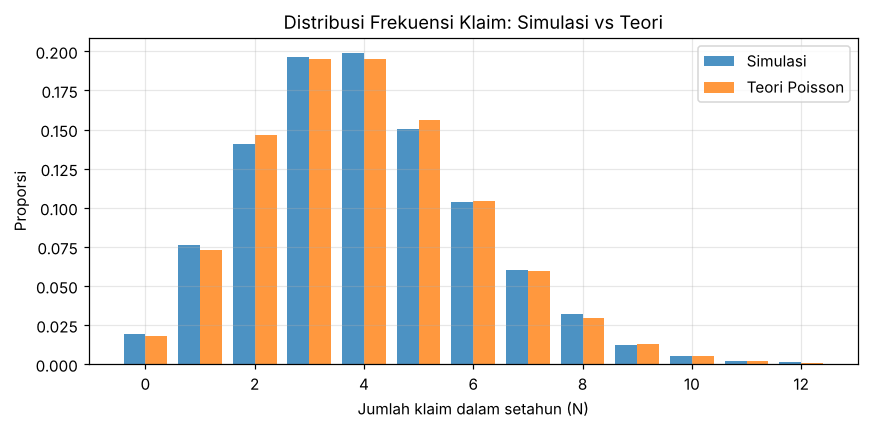

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(k - 0.2, freq_table["Simulasi"], width=0.4, label="Simulasi", alpha=0.8)
ax.bar(k + 0.2, freq_table["Teori Poisson"], width=0.4, label="Teori Poisson", alpha=0.8)
ax.set_xlabel("Jumlah klaim dalam setahun (N)")
ax.set_ylabel("Proporsi")
ax.set_title("Distribusi Frekuensi Klaim: Simulasi vs Teori")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_claim_frequency.png", dpi=150)
plt.show()

**Interpretasi (aktuaria).**

- Rata-rata dan varians simulasi sama-sama mendekati $\lambda = 4$. Ini ciri khas Poisson (mean = varians) dan menandakan pembangkit acak bekerja benar.
- Batang simulasi dan teori hampir berimpit. Selisih kecil yang tersisa adalah **galat sampling** yang wajar pada 10.000 undian.
- Modus (jumlah klaim paling sering) berada di sekitar 3 sampai 4 klaim, tetapi tahun dengan 8 atau lebih klaim tetap mungkin terjadi, walau jarang.
- **Peluang tahun tanpa klaim** adalah $P(N=0) = e^{-4} \approx 1{,}83\%$. Konsekuensinya penting: pada sebagian kecil tahun, total kerugian tepat **nol**. Kita akan melihatnya kembali di Bagian 10.

## 8. Claim Severity Modeling

**Konsep.** Komponen kedua: besar satu klaim. Kita undi $X \sim \text{Lognormal}(\mu=10,\ \sigma=0.8)$ dan membandingkannya dengan sifat teoretisnya.

Pada `numpy`, `rng.lognormal(mean, sigma)` menerima parameter dari **distribusi normal pada skala log**, yaitu $\mu$ dan $\sigma$ yang sama dengan definisi kita. Pada `scipy`, bentuk setaranya adalah `lognorm(s=sigma, scale=exp(mu))`.

In [5]:
rng = np.random.default_rng(SEED)
X = rng.lognormal(MU, SIGMA, size=N_SIMS)

# Sifat teoretis
mean_x   = np.exp(MU + SIGMA**2 / 2)
median_x = np.exp(MU)
sd_x     = np.sqrt((np.exp(SIGMA**2) - 1) * np.exp(2*MU + SIGMA**2))

sev_table = pd.DataFrame({
    "Simulasi": [X.mean(), np.median(X), X.std(ddof=1)],
    "Teori":    [mean_x, median_x, sd_x],
}, index=["Mean", "Median", "Std. Deviasi"])
sev_table["Selisih (%)"] = 100 * (sev_table["Simulasi"] / sev_table["Teori"] - 1)
sev_table

,Simulasi,Teori,Selisih (%)
Mean,"30,222.79","30,333.26",-0.36
Median,"21,795.66","22,026.47",-1.05
Std. Deviasi,"29,010.84","28,720.34",1.01


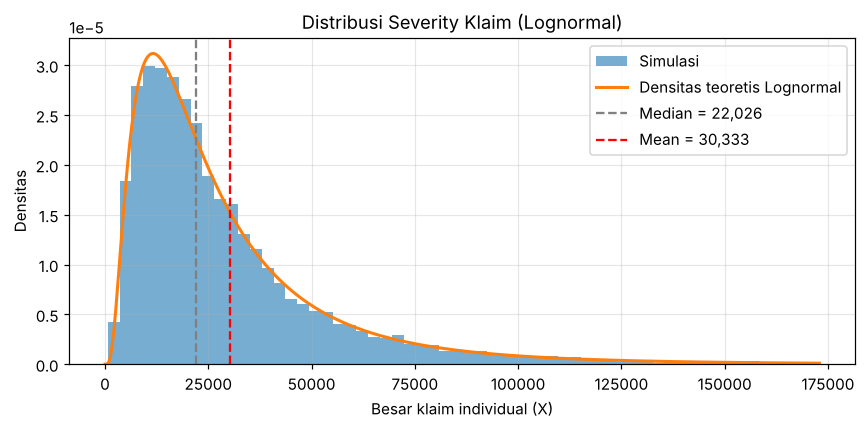

P50 (median)    22,026.47
P90             61,404.68
P99            141,644.87
P99.9          260,976.55
Name: Kuantil teoretis klaim individual, dtype: float64

In [6]:
dist = stats.lognorm(s=SIGMA, scale=np.exp(MU))
x_max = dist.ppf(0.995)
xs = np.linspace(0, x_max, 400)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X[X <= x_max], bins=60, density=True, alpha=0.6, label="Simulasi")
ax.plot(xs, dist.pdf(xs), lw=2, label="Densitas teoretis Lognormal")
ax.axvline(median_x, ls="--", color="gray", label=f"Median = {median_x:,.0f}")
ax.axvline(mean_x, ls="--", color="red", label=f"Mean = {mean_x:,.0f}")
ax.set_xlabel("Besar klaim individual (X)")
ax.set_ylabel("Densitas")
ax.set_title("Distribusi Severity Klaim (Lognormal)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_claim_severity.png", dpi=150)
plt.show()

pd.Series({"P50 (median)": dist.ppf(0.5), "P90": dist.ppf(0.9),
           "P99": dist.ppf(0.99), "P99.9": dist.ppf(0.999)},
          name="Kuantil teoretis klaim individual")

**Interpretasi (aktuaria).**

- Histogram simulasi menempel pada kurva teoretis. Distribusi severity yang kita bangkitkan sudah benar.
- Bentuknya **miring ke kanan**: median klaim sekitar **22.026**, sedangkan rata-ratanya sekitar **30.333**. Rata-rata lebih besar dari median karena segelintir klaim besar "menarik" rata-rata ke atas.
- Klaim tipikal ada di kisaran puluhan ribu, tetapi ekornya panjang: sekitar 1 dari 100 klaim melebihi 142 ribu, dan sekitar 1 dari 1.000 klaim melebihi 261 ribu (lihat tabel kuantil).
- Secara praktis: **median menggambarkan klaim "biasa", mean menggambarkan beban rata-rata jangka panjang.** Premi harus mengikuti mean, bukan median.
- Simpangan baku klaim individual (sekitar 28.700) hampir sama dengan mean-nya. Ini menunjukkan variabilitas severity yang tinggi.

## 9. Monte Carlo Simulation

**Konsep.** Sekarang kedua komponen digabung. Satu iterasi = satu tahun hipotetis:

1. Undi $N$ (berapa klaim).
2. Undi $N$ besar klaim $X_1,\dots,X_N$.
3. Jumlahkan menjadi $S$.

### 9.1 Satu tahun hipotetis (agar mekanismenya terlihat jelas)

In [7]:
rng_demo = np.random.default_rng(2024)

n_demo = rng_demo.poisson(LAMBDA)
claims_demo = rng_demo.lognormal(MU, SIGMA, size=n_demo)

print(f"Jumlah klaim tahun ini : {n_demo}")
for i, c in enumerate(claims_demo, 1):
    print(f"  Klaim ke-{i}: {c:>12,.0f}")
print(f"Total kerugian tahun ini (S) : {claims_demo.sum():,.0f}")

Jumlah klaim tahun ini : 5
  Klaim ke-1:       43,874
  Klaim ke-2:       33,102
  Klaim ke-3:       93,735
  Klaim ke-4:       40,162
  Klaim ke-5:       36,747
Total kerugian tahun ini (S) : 247,620


### 9.2 Versi eksplisit dengan *for-loop* (mudah dibaca, lambat)

Berikut implementasi paling literal: ulangi proses di atas 10.000 kali.

In [8]:
rng_loop = np.random.default_rng(SEED)

S_loop = np.empty(N_SIMS)
for t in range(N_SIMS):
    n_claims = rng_loop.poisson(LAMBDA)
    claims = rng_loop.lognormal(MU, SIGMA, size=n_claims)
    S_loop[t] = claims.sum()

print(f"[Loop]  mean = {S_loop.mean():,.0f} | std = {S_loop.std(ddof=1):,.0f}")

[Loop]  mean = 122,269 | std = 84,083


### 9.3 Versi vektor (cepat) dari `src/simulation.py`

Fungsi `simulate_aggregate_loss` melakukan hal yang sama **tanpa loop Python**: semua klaim dari semua tahun diundi sekaligus, lalu `np.bincount` menjumlahkan klaim per tahun. Tahun tanpa klaim otomatis bernilai 0.

In [9]:
S, N = simulate_aggregate_loss(LAMBDA, MU, SIGMA, N_SIMS, SEED)

print(f"[Vektor] mean = {S.mean():,.0f} | std = {S.std(ddof=1):,.0f}")

results = pd.DataFrame({"jumlah_klaim": N, "total_kerugian": S})
results.head(8)

[Vektor] mean = 121,545 | std = 84,862


,jumlah_klaim,total_kerugian
0,6,"161,831.66"
1,3,"91,509.69"
2,6,"358,417.68"
3,8,"368,212.15"
4,1,"25,642.29"
5,6,"113,330.82"
6,2,"38,307.41"
7,7,"187,462.23"


**Interpretasi.**

- Versi loop dan versi vektor menghasilkan mean dan standar deviasi yang **mirip**, tetapi tidak identik angkanya. Itu wajar: keduanya memakai urutan bilangan acak yang berbeda. Yang harus sama adalah **distribusinya**, bukan nilai tiap iterasi.
- Perhatikan pada tabel di atas bahwa total kerugian sangat bergantung pada dua hal: jumlah klaim **dan** apakah ada klaim besar di antaranya. Tahun dengan 4 klaim kecil bisa lebih ringan daripada tahun dengan 2 klaim yang salah satunya sangat besar.
- Versi vektor dipakai untuk analisis selanjutnya karena jauh lebih cepat; ini penting ketika jumlah simulasi dinaikkan menjadi jutaan.

## 10. Statistical Analysis and Risk Measurement

### 10.1 Validasi: simulasi vs teori

Karena $E[S]=\lambda E[X]$ dan $\mathrm{Var}(S)=\lambda E[X^2]$ diketahui, kita bisa menguji kebenaran simulasi.

In [10]:
th = theoretical_moments(LAMBDA, MU, SIGMA)
se_mean = S.std(ddof=1) / np.sqrt(N_SIMS)

validation = pd.DataFrame({
    "Simulasi": [S.mean(), S.std(ddof=1)],
    "Teori":    [th["E[S]"], th["SD(S)"]],
}, index=["Expected Annual Loss  E[S]", "Std. Deviasi  SD(S)"])
validation["Selisih (%)"] = 100 * (validation["Simulasi"] / validation["Teori"] - 1)
display(validation)

print(f"Standard error rata-rata  : {se_mean:,.0f}")
print(f"Interval kepercayaan 95%  : {S.mean() - 1.96*se_mean:,.0f}  s.d.  {S.mean() + 1.96*se_mean:,.0f}")
print(f"Nilai teoretis E[S]       : {th['E[S]']:,.0f}")

skew = ((S - S.mean())**3).mean() / S.std()**3
print(f"\nSkewness simulasi         : {skew:.2f}")
print(f"Median total kerugian     : {np.median(S):,.0f}")
print(f"Tahun tanpa klaim         : {(N == 0).sum()} dari {N_SIMS:,}  ({(N == 0).mean():.2%};  teori = {np.exp(-LAMBDA):.2%})")
print(f"Kerugian maksimum         : {S.max():,.0f}")

,Simulasi,Teori,Selisih (%)
Expected Annual Loss E[S],"121,545.37","121,333.03",0.18
Std. Deviasi SD(S),"84,862.32","83,545.54",1.58


Standard error rata-rata  : 849
Interval kepercayaan 95%  : 119,882  s.d.  123,209
Nilai teoretis E[S]       : 121,333

Skewness simulasi         : 1.37
Median total kerugian     : 105,842
Tahun tanpa klaim         : 196 dari 10,000  (1.96%;  teori = 1.83%)
Kerugian maksimum         : 806,501


### 10.2 VaR dan TVaR

In [11]:
expected_loss = S.mean()
rows = []
for level in (0.95, 0.99):
    v = value_at_risk(S, level)
    t = tail_value_at_risk(S, level)
    rows.append({
        "Tingkat": f"{level:.0%}",
        "VaR": v,
        "TVaR": t,
        "TVaR - VaR": t - v,
        "VaR - E[S]": v - expected_loss,
        "TVaR - E[S]": t - expected_loss,
        "VaR / E[S]": v / expected_loss,
        "TVaR / E[S]": t / expected_loss,
    })
risk_table = pd.DataFrame(rows).set_index("Tingkat")
risk_table

,VaR,TVaR,TVaR - VaR,VaR - E[S],TVaR - E[S],VaR / E[S],TVaR / E[S]
Tingkat,,,,,,,
95%,"282,167.74","353,576.87","71,409.13","160,622.36","232,031.49",2.32,2.91
99%,"390,997.05","472,494.81","81,497.76","269,451.67","350,949.43",3.22,3.89


**Interpretasi (aktuaria).**

*Validasi.*
- Rata-rata simulasi (**121.545**) hanya berbeda sekitar **0,2%** dari nilai teoretis (**121.333**). Nilai teoretis ini berada di dalam interval kepercayaan 95% hasil simulasi, sehingga simulasi **konsisten dengan teori**.
- Standar deviasi simulasi (**84.862**) sedikit lebih besar (sekitar 1,6%) dibanding teori (**83.546**). Estimasi varians lebih sensitif terhadap klaim ekstrem dibanding estimasi mean, jadi selisih yang sedikit lebih besar ini masih wajar.

*Bentuk distribusi.*
- Median total kerugian (**105.842**) lebih kecil dari mean (**121.545**) dan skewness positif (**1,37**): distribusinya **miring ke kanan**. Artinya "tahun biasa" lebih ringan dari rata-rata, tetapi ada tahun-tahun buruk yang jauh lebih berat.
- Sekitar **1,96%** tahun tanpa klaim sama sekali (teori 1,83%), sesuai $e^{-4}$.

*Ukuran risiko.*
- **Expected loss ≈ 121.545** → dasar *pure premium* (sebelum biaya, margin, dan keuntungan).
- **VaR 95% ≈ 282.168**: dalam 95% tahun, total kerugian tidak melebihi angka ini; hanya 1 dari 20 tahun yang lebih buruk.
- **VaR 99% ≈ 390.997**: sekitar 3,2 kali expected loss. Untuk kuat menahan 99% skenario, dibutuhkan **dana cadangan sekitar 269.000 di atas expected loss** (VaR − E[S]).
- **TVaR 99% ≈ 472.495** lebih besar dari VaR 99% sekitar 81.500. Ini mengatakan: *jika* kita sudah masuk 1% tahun terburuk, rata-rata kerugiannya sekitar 472 ribu, bukan 391 ribu. **VaR tidak memberi tahu seberapa parah ekornya; TVaR memberi tahu.**
- Selalu TVaR ≥ VaR, dan selisihnya makin besar pada tingkat kepercayaan yang lebih tinggi karena ekor yang dirata-ratakan semakin ekstrem.

## 11. Visualization and Interpretation

### 11.1 Distribusi total kerugian

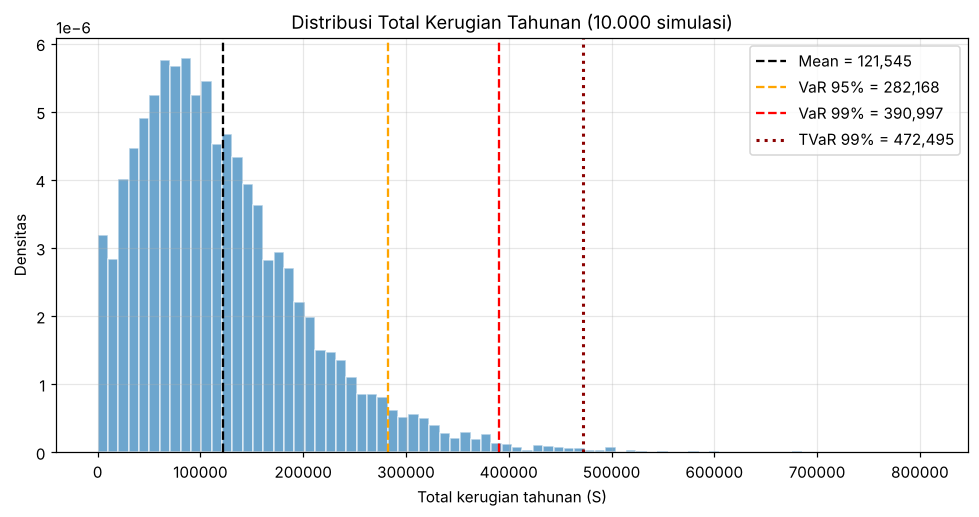

In [12]:
var95, var99 = value_at_risk(S, 0.95), value_at_risk(S, 0.99)
tvar99 = tail_value_at_risk(S, 0.99)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(S, bins=80, density=True, alpha=0.65, edgecolor="white")
ax.axvline(S.mean(), color="black", ls="--", label=f"Mean = {S.mean():,.0f}")
ax.axvline(var95, color="orange", ls="--", label=f"VaR 95% = {var95:,.0f}")
ax.axvline(var99, color="red", ls="--", label=f"VaR 99% = {var99:,.0f}")
ax.axvline(tvar99, color="darkred", ls=":", lw=2, label=f"TVaR 99% = {tvar99:,.0f}")
ax.set_xlabel("Total kerugian tahunan (S)")
ax.set_ylabel("Densitas")
ax.set_title("Distribusi Total Kerugian Tahunan (10.000 simulasi)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig3_aggregate_loss_distribution.png", dpi=150)
plt.show()

**Cara membaca grafik.** Sebagian besar "tahun" berkumpul di kisaran 50 ribu sampai 200 ribu, lalu ada **ekor panjang ke kanan**. Garis VaR 95% dan 99% menandai batas tahun-tahun buruk, dan TVaR 99% menandai rata-rata kerugian di dalam ekor tersebut. Bentuk seperti ini adalah ciri khas portofolio asuransi: **risiko tidak simetris**, sehingga hanya melihat mean akan meremehkan bahaya di sisi kanan.

### 11.2 Analisis konvergensi: kapan simulasi cukup banyak?

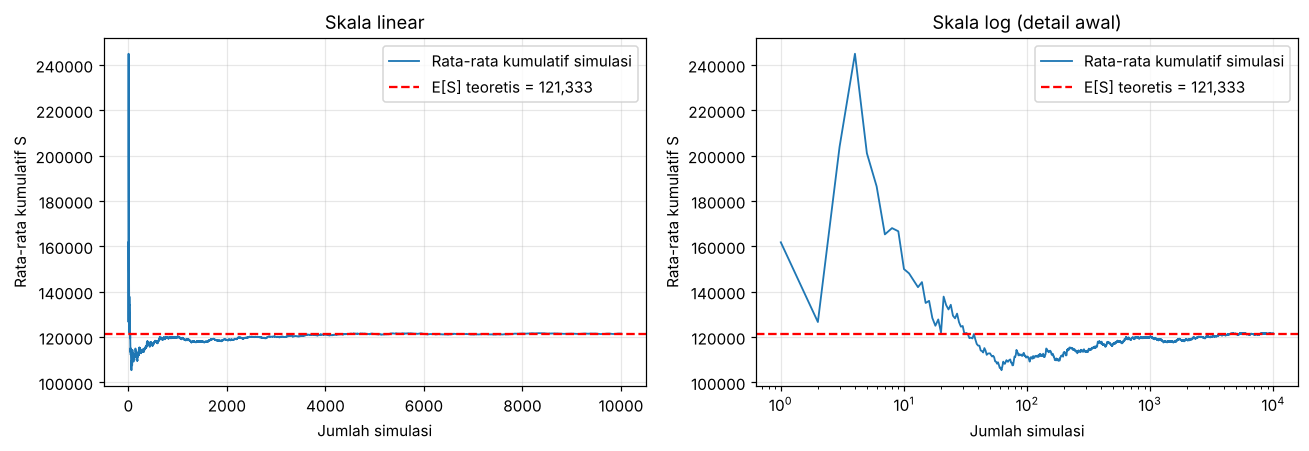

n =    100  rata-rata =    111,257   selisih vs teori = -8.30%
n =  1,000  rata-rata =    120,350   selisih vs teori = -0.81%
n = 10,000  rata-rata =    121,545   selisih vs teori = +0.18%


In [13]:
rm = running_mean(S)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, log in zip(axes, (False, True)):
    ax.plot(np.arange(1, N_SIMS + 1), rm, lw=1.2, label="Rata-rata kumulatif simulasi")
    ax.axhline(th["E[S]"], color="red", ls="--", label=f"E[S] teoretis = {th['E[S]']:,.0f}")
    ax.set_xlabel("Jumlah simulasi")
    ax.set_ylabel("Rata-rata kumulatif S")
    if log:
        ax.set_xscale("log"); ax.set_title("Skala log (detail awal)")
    else:
        ax.set_title("Skala linear")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig4_convergence.png", dpi=150)
plt.show()

for n in (100, 1_000, 10_000):
    print(f"n = {n:>6,}  rata-rata = {rm[n-1]:>10,.0f}   selisih vs teori = {100*(rm[n-1]/th['E[S]']-1):+.2f}%")

Rata-rata kumulatif bergoyang cukup liar pada awal (dengan 100 simulasi, rata-rata baru sekitar 111 ribu atau sekitar 8% di bawah teori), lalu **menyempit dan menempel pada garis teoretis** seiring bertambahnya simulasi (1.000 simulasi: sekitar 120 ribu; 10.000 simulasi: sekitar 121,5 ribu). Ini adalah wujud nyata *Law of Large Numbers*.

Namun konvergensi **mean** tidak sama dengan konvergensi **ukuran ekor**. Uji berikut mengulang simulasi dengan banyak seed berbeda untuk melihat seberapa stabil setiap estimasi.

In [14]:
# (a) Stabilitas estimasi pada N_SIMS = 10.000, diulang untuk 200 seed berbeda
rows = []
for sd in range(200):
    s, _ = simulate_aggregate_loss(LAMBDA, MU, SIGMA, N_SIMS, seed=sd)
    rows.append([s.mean(), value_at_risk(s, .95), value_at_risk(s, .99),
                 tail_value_at_risk(s, .95), tail_value_at_risk(s, .99)])
stab = pd.DataFrame(rows, columns=["Mean", "VaR 95%", "VaR 99%", "TVaR 95%", "TVaR 99%"])
stability = pd.DataFrame({
    "Rata-rata estimasi": stab.mean(),
    "Std. dev antar-seed": stab.std(),
    "Persentil 5": stab.quantile(0.05),
    "Persentil 95": stab.quantile(0.95),
})
stability["Std. dev / rata-rata (%)"] = 100 * stability["Std. dev antar-seed"] / stability["Rata-rata estimasi"]
display(stability)

# (b) Pengaruh jumlah simulasi terhadap ketelitian VaR 99% (100 seed per ukuran)
conv = []
for n in (1_000, 10_000, 100_000):
    v = [value_at_risk(simulate_aggregate_loss(LAMBDA, MU, SIGMA, n, seed=s)[0], .99) for s in range(100)]
    conv.append({"N simulasi": n, "Rata-rata VaR 99%": np.mean(v), "Std. dev antar-seed": np.std(v)})
pd.DataFrame(conv).set_index("N simulasi")

,Rata-rata estimasi,Std. dev antar-seed,Persentil 5,Persentil 95,Std. dev / rata-rata (%)
Mean,"121,386.03",814.38,"120,054.45","122,642.79",0.67
VaR 95%,"278,934.49","3,020.01","273,678.27","283,862.79",1.08
VaR 99%,"386,607.14","6,250.82","376,289.17","397,230.74",1.62
TVaR 95%,"346,754.72","4,294.40","339,759.00","353,587.70",1.24
TVaR 99%,"457,026.87","10,398.48","440,311.50","474,005.47",2.28


,Rata-rata VaR 99%,Std. dev antar-seed
N simulasi,,
1000,"381,257.11","18,157.98"
10000,"386,808.57","6,251.39"
100000,"386,216.61","2,226.14"


**Interpretasi.**

- Pada 10.000 simulasi, **mean** sangat stabil (variasi antar-seed hanya sekitar 0,7%), sedangkan **ukuran ekor kurang stabil**: VaR 99% bervariasi sekitar 1,6% dan **TVaR 99% sekitar 2,3%** (rentang persentil 5 sampai 95 untuk TVaR 99% kira-kira 440 ribu sampai 474 ribu). Alasannya sederhana: VaR 99% hanya bertumpu pada sekitar 100 titik data paling ekstrem.
- Menambah simulasi memperbaiki ketelitian sesuai $1/\sqrt{n}$: simpangan baku VaR 99% turun dari sekitar **18.000** (1.000 simulasi), ke **6.300** (10.000), ke **2.200** (100.000).
- Implikasi praktis: angka VaR/TVaR pada proyek ini sebaiknya dilaporkan sebagai **perkiraan dengan galat**, bukan angka pasti. Untuk pelaporan serius, gunakan 100.000 simulasi atau lebih.

### 11.3 Sensitivitas terhadap parameter

Apa yang terjadi bila asumsi kita berubah? (seed tetap 42 pada tiap skenario)

In [15]:
scenarios = {
    "Dasar (λ=4, σ=0.8)":            dict(lam=4, sigma=0.8),
    "Frekuensi 2x (λ=8, σ=0.8)":     dict(lam=8, sigma=0.8),
    "Severity lebih liar (σ=1.2)":   dict(lam=4, sigma=1.2),
    "Severity lebih tenang (σ=0.5)": dict(lam=4, sigma=0.5),
}
rows = []
for name, p in scenarios.items():
    s, _ = simulate_aggregate_loss(lam=p["lam"], mu=MU, sigma=p["sigma"], n_sims=N_SIMS, seed=SEED)
    rows.append({
        "Skenario": name,
        "Mean": s.mean(),
        "Std. dev": s.std(ddof=1),
        "Koef. variasi": s.std(ddof=1) / s.mean(),
        "VaR 99%": value_at_risk(s, .99),
        "TVaR 99%": tail_value_at_risk(s, .99),
    })
sens = pd.DataFrame(rows).set_index("Skenario")
sens

,Mean,Std. dev,Koef. variasi,VaR 99%,TVaR 99%
Skenario,,,,,
"Dasar (λ=4, σ=0.8)","121,545.37","84,862.32",0.70,"390,997.05","472,494.81"
"Frekuensi 2x (λ=8, σ=0.8)","243,398.88","120,187.01",0.49,"604,100.29","688,729.76"
Severity lebih liar (σ=1.2),"182,516.63","191,881.97",1.05,"903,641.54","1,281,448.06"
Severity lebih tenang (σ=0.5),"99,844.51","57,105.51",0.57,"265,595.78","295,892.50"


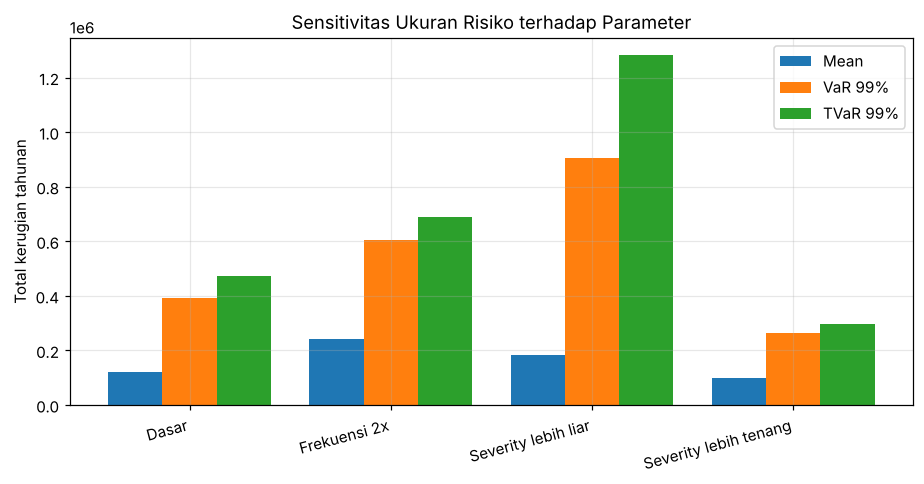

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
w = 0.27
x = np.arange(len(sens))
ax.bar(x - w, sens["Mean"], w, label="Mean")
ax.bar(x,     sens["VaR 99%"], w, label="VaR 99%")
ax.bar(x + w, sens["TVaR 99%"], w, label="TVaR 99%")
ax.set_xticks(x)
ax.set_xticklabels([n.split(" (")[0] for n in sens.index], rotation=15, ha="right")
ax.set_ylabel("Total kerugian tahunan")
ax.set_title("Sensitivitas Ukuran Risiko terhadap Parameter")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig5_sensitivity.png", dpi=150)
plt.show()

**Interpretasi (aktuaria).**

| Perubahan asumsi | Dampak | Penalaran |
|---|---|---|
| **Frekuensi 2×** (λ = 8) | Mean menjadi 2×, tetapi standar deviasi hanya naik sekitar 1,4×; koefisien variasi turun dari 0,70 ke sekitar 0,49 | Risiko **terdiversifikasi**: makin banyak klaim, makin "terata-ratakan". Inilah prinsip dasar asuransi (*law of large numbers*) |
| **σ naik ke 1,2** | Mean naik sekitar 50%, tetapi **TVaR 99% melonjak dari sekitar 472 ribu menjadi sekitar 1,28 juta** (sekitar 2,7×) | Ekor severity yang lebih tebal berdampak **jauh lebih besar pada risiko ekstrem** dibanding pada rata-rata |
| **σ turun ke 0,5** | Mean turun ke sekitar 99.800 dan TVaR 99% ke sekitar 296 ribu | Klaim lebih seragam → ekor lebih tipis → kebutuhan cadangan jauh lebih kecil |

**Pelajaran utama:** perubahan kecil pada parameter severity ($\sigma$) mengubah **kebutuhan modal** jauh lebih drastis daripada mengubah premi dasar. Karena itu, pemilihan dan estimasi distribusi severity adalah salah satu keputusan paling berisiko dalam pemodelan aktuaria.

## 12. Conclusion and Further Development

### Kesimpulan

1. **Model berfungsi dan tervalidasi.** Mean simulasi (121.545) sangat dekat dengan nilai teoretis (121.333), dan standar deviasi simulasi (84.862) dekat dengan teori (83.546).
2. **Distribusi total kerugian miring ke kanan.** Median (105.842) < mean (121.545), dengan ekor kanan panjang: tahun buruk bisa beberapa kali lipat lebih parah dari tahun rata-rata.
3. **Ukuran risiko (seed 42, 10.000 simulasi):**

| | 95% | 99% |
|---|---|---|
| VaR | ≈ 282.168 | ≈ 390.997 |
| TVaR | ≈ 353.577 | ≈ 472.495 |

4. **TVaR memberi gambaran ekor yang tidak ditangkap VaR**; selisihnya makin besar di tingkat kepercayaan tinggi.
5. **Estimasi ekor kurang stabil dibanding estimasi mean**, sehingga hasil VaR/TVaR harus dibaca dengan memperhitungkan galat simulasi.
6. **Parameter severity sangat memengaruhi risiko ekstrem** (sensitivitas σ).

> Angka pada bagian interpretasi mengacu pada `SEED = 42` dan `N_SIMS = 10_000`. Jika Anda mengubah seed atau parameter, angka akan berubah sedikit dan teks interpretasi perlu disesuaikan.

### Keterbatasan

- Parameter bersifat ilustratif, belum diestimasi dari data.
- Asumsi independensi antar-klaim dan antara frekuensi dengan severity; tidak ada korelasi, tren, atau inflasi.
- Satu portofolio homogen, satu periode, tanpa diskonto.
- Tanpa *deductible*, limit polis, maupun reinsurance.
- Poisson mengasumsikan mean = varians; Lognormal mungkin meremehkan ekor yang sangat tebal.

### Pengembangan lanjutan

| Tahap | Ide |
|---|---|
| Data nyata | Gunakan dataset klaim publik; estimasi parameter dengan MLE dan uji kecocokan (Kolmogorov-Smirnov, QQ-plot) |
| Frekuensi | Bandingkan Poisson dengan Negative Binomial bila data *overdispersed* |
| Severity | Bandingkan Lognormal, Gamma, Weibull, Pareto |
| Struktur polis | Tambahkan *deductible*, limit, dan **reinsurance** (*excess of loss*, *stop loss*) |
| Metode pembanding | Bandingkan dengan **Panjer recursion** atau aproksimasi (misalnya Normal Power) |
| Pelaporan | Tambahkan ringkasan visual interaktif atau dasbor |